# CVA, DVA y riesgo de correlación adversa

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la exposición de un swap)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- convertir un spread de crédito en una curva de supervivencia y una probabilidad de incumplimiento por tramo con el triángulo de crédito;
- calcular el CVA y el DVA unilaterales como una suma sobre tramos de tiempo, y decir por qué la curva de crédito usada aquí es un proxy;
- enunciar la tasa de riesgo de Hull y White que depende del valor de la cartera, y calibrar su parte dependiente del tiempo de forma secuencial;
- medir cuánto cambia el CVA con el parámetro de correlación adversa $b$, y comprobar que $b=0$ da exactamente el CVA independiente;
- reproducir el ejemplo de tres trayectorias del Apéndice del artículo hasta sus dígitos impresos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son dos variantes del caso C12 (riesgo de crédito de contraparte): el conjunto de neteo sin garantía de cuatro swaps sintéticos, y la variante de correlación adversa que agrega el barrido sobre $b$. Ambas usan la curva del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`).

- **Archivos que se leen:** `data/derived/C12/netting-set.json` (curva, calibración, swaps y el bloque de CVA) y `data/derived/C12/wrong-way-risk.json` (la misma cartera y el barrido sobre $b$).
- **La curva de crédito es un proxy.** La curva de spreads de la contraparte es la curva spot corporativa HQM del Tesoro menos la curva cero del Tesoro del mismo fin de mes: un promedio de mercado AAA a A, un piso para calificaciones menores y no la curva de ninguna contraparte (ítem R10 de la investigación). Un spread negativo se fijaría en cero y se contaría. El spread propio del banco es un parámetro con nombre, plano, de 0,8%, y ambas pérdidas dado el incumplimiento son 60%, todo rotulado `convention`.
- **Qué se calcula aquí:** la supervivencia, las probabilidades de incumplimiento y el CVA se recalculan desde los spreads versionados y la exposición esperada descontada versionada; el barrido de correlación adversa se recalcula desde la simulación, que este cuaderno reconstruye.

La celda siguiente carga ambos documentos e imprime el bloque de crédito.

In [2]:
# Cargar los dos documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir el bloque de crédito
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
base_doc = json.loads((derived / "netting-set.json").read_text(encoding="utf-8"))
wwr_doc = json.loads((derived / "wrong-way-risk.json").read_text(encoding="utf-8"))
base, wwr = base_doc["outputs"], wwr_doc["outputs"]
credit = base["cva_dva"]

print("calculado con riskvalidation", base_doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("fuente de la curva de crédito:", credit["credit_curve_source"])
print("fórmula de supervivencia:", credit["survival_formula"], "| spreads llevados a cero:", credit["spreads_floored_at_zero"])
print("LGD:", credit["lgd"], "| LGD del banco:", credit["bank_lgd"], "| spread del banco:", base["named_parameters"]["bank_spread"]["value"])
print("tramos de tiempo:", len(credit["buckets"]))
for b in credit["buckets"][:2] + credit["buckets"][-1:]:
    print(f"  [{b['t_start']:.3f}, {b['t_end']:.3f}] spread {b['spread']:.6f} | supervivencia {b['survival']:.6f} | PD {b['pd_counterparty']:.6f} | EPE {b['epe_discounted']:.0f}")

calculado con riskvalidation 1.0.1 | instalado 1.0.1
fuente de la curva de crédito: hqm-minus-treasury
fórmula de supervivencia: S(t) = exp(-s t / LGD) | spreads llevados a cero: 0
LGD: 0.6 | LGD del banco: 0.6 | spread del banco: 0.008
tramos de tiempo: 33
  [0.000, 0.083] spread 0.001667 | supervivencia 0.999768 | PD 0.000232 | EPE 12667
  [0.083, 0.167] spread 0.001667 | supervivencia 0.999537 | PD 0.000231 | EPE 23970
  [9.000, 9.500] spread 0.006887 | supervivencia 0.896690 | PD 0.007278 | EPE 36366


## Método

### Paso 1: de un spread a una curva de supervivencia

Para probabilidades de incumplimiento pequeñas, el **triángulo de crédito** dice que la tasa de riesgo es el spread dividido por la pérdida dado el incumplimiento, $\lambda = s/\mathrm{LGD}$, y la supervivencia hasta $t$ es $S(t) = e^{-s\,t/\mathrm{LGD}}$ (Hull y White, 2012, página 13). La probabilidad de incumplimiento de un tramo es la caída de la supervivencia a través de él:

$$PD(t_{i-1}, t_i) = S(t_{i-1}) - S(t_i)$$

`survival_from_spread` y `default_probabilities`, del motor, las calculan. Los spreads se leen de los tramos versionados. La celda siguiente recalcula la supervivencia y las probabilidades de incumplimiento y las compara con las versionadas.

In [3]:
# Recalcular la curva de supervivencia y las probabilidades de incumplimiento por tramo desde los spreads versionados y compararlas con las versionadas
buckets = credit["buckets"]
report = np.array([b["t_end"] for b in buckets])
times = np.concatenate([[0.0], report])
spreads = np.array([buckets[0]["spread"]] + [b["spread"] for b in buckets])
lgd, bank_lgd = credit["lgd"], credit["bank_lgd"]

survival = cva.survival_from_spread(spreads, times, lgd)
pd_cp = cva.default_probabilities(survival)
print("brecha de la supervivencia con los tramos versionados:", float(np.max(np.abs(survival[1:] - [b["survival"] for b in buckets]))))
print("brecha de la PD con los tramos versionados:", float(np.max(np.abs(pd_cp - [b["pd_counterparty"] for b in buckets]))))
for years in (1.0, 5.0, 9.5):
    k = int(np.searchsorted(times, years - 1e-9))
    print(f"t = {years:4.1f} | spread {spreads[k]:.5f} | riesgo s/LGD {spreads[k] / lgd:.5f} | S(t) = {survival[k]:.5f} | 1 - S(t) = {1 - survival[k]:.5f}")
print("las PD de los tramos suman 1 - S(T):", round(float(pd_cp.sum()), 8), "=", round(float(1 - survival[-1]), 8))

brecha de la supervivencia con los tramos versionados: 0.0
brecha de la PD con los tramos versionados: 0.0
t =  1.0 | spread 0.00306 | riesgo s/LGD 0.00509 | S(t) = 0.99492 | 1 - S(t) = 0.00508
t =  5.0 | spread 0.00512 | riesgo s/LGD 0.00854 | S(t) = 0.95822 | 1 - S(t) = 0.04178
t =  9.5 | spread 0.00689 | riesgo s/LGD 0.01148 | S(t) = 0.89669 | 1 - S(t) = 0.10331
las PD de los tramos suman 1 - S(T): 0.10331047 = 0.10331047


### Paso 2: CVA y DVA

Con la exposición positiva esperada descontada $\mathrm{EPE}(t_i)$ y la exposición negativa $\mathrm{ENE}(t_i)$ del cuaderno 01, y suponiendo que exposición e incumplimiento son independientes (metodología de ORE, la discretización avanzada):

$$\mathrm{CVA} = \sum_i PD(t_{i-1},t_i)\ \mathrm{LGD}\ \mathrm{EPE}(t_i), \qquad \mathrm{DVA} = \sum_i PD_{banco}(t_{i-1},t_i)\ \mathrm{LGD}_{banco}\ \mathrm{ENE}(t_i)$$

El CVA es un costo positivo y el DVA un beneficio positivo; el valor bilateral simple es $\mathrm{BCVA} = \mathrm{CVA} - \mathrm{DVA}$ (la forma de primer incumplimiento no está implementada). `cva` y `dva`, del motor, devuelven el total y los términos por tramo. La celda siguiente calcula ambos desde los perfiles descontados versionados y los compara con el documento, y luego reemplaza la curva proxy por un spread plano de 125 pb, el valor del ejemplo de Hull y White, para mostrar cuánto descansa la respuesta en la curva de crédito.

In [4]:
# CVA y DVA desde los perfiles descontados versionados, contra el documento, y el CVA con un spread plano de 125 pb
epe_d = np.array(base["exposure"]["ee_discounted"]["values"])
ene_d = np.array(base["exposure"]["ene_discounted"]["values"])
bank_spread = base["named_parameters"]["bank_spread"]["value"]
survival_bank = cva.survival_from_spread(np.full(times.size, bank_spread), times, bank_lgd)
pd_bank = cva.default_probabilities(survival_bank)

cva_value, cva_terms = cva.cva(epe_d, pd_cp, lgd)
dva_value, dva_terms = cva.dva(ene_d, pd_bank, bank_lgd)
print("CVA:", round(cva_value, 2), "| versionado", round(credit["cva"]["amount"], 2), "| brecha", abs(cva_value - credit["cva"]["amount"]))
print("DVA:", round(dva_value, 2), "| versionado", round(credit["dva"]["amount"], 2), "| brecha", abs(dva_value - credit["dva"]["amount"]))
print("BCVA = CVA - DVA:", round(cva_value - dva_value, 2), "| versionado", round(credit["bcva"]["amount"], 2))
print("error de Monte Carlo del CVA (versionado):", round(credit["cva"]["mc_se"], 2))
print("parte del CVA de los dos primeros años:", round(float(cva_terms[report <= 2.0].sum() / cva_value), 3))
print("el CVA es cero con spread cero:", cva.cva(epe_d, cva.default_probabilities(cva.survival_from_spread(np.zeros(times.size), times, lgd)), lgd)[0])

flat = cva.default_probabilities(cva.survival_from_spread(np.full(times.size, 0.0125), times, lgd))
print("CVA con un spread plano de 125 pb:", round(cva.cva(epe_d, flat, lgd)[0], 2), "| razón con la curva proxy:", round(cva.cva(epe_d, flat, lgd)[0] / cva_value, 2))

CVA: 9477.77 | versionado 9477.77 | brecha 0.0
DVA: 4344.1 | versionado 4344.1 | brecha 0.0
BCVA = CVA - DVA: 5133.67 | versionado 5133.67
error de Monte Carlo del CVA (versionado): 51.05
parte del CVA de los dos primeros años: 0.088
el CVA es cero con spread cero: 0.0
CVA con un spread plano de 125 pb: 16506.36 | razón con la curva proxy: 1.74


### Paso 3: correlación adversa, la tasa de riesgo de Hull y White

El riesgo de correlación adversa es la dependencia entre exposición e incumplimiento: cuando la contraparte debe más, es más probable que incumpla. Hull y White (2012) lo modelan haciendo que la tasa de riesgo dependa del valor $w$ de la cartera:

$$h(t) = \exp\big[a(t) + b\,w(t)\big]$$

Un $b$ positivo es correlación adversa, uno negativo es correlación favorable, y $b=0$ es independencia. La función $a(t)$ no es libre: se calibra, tramo a tramo, para que la supervivencia promedio sobre las trayectorias simuladas iguale la supervivencia implícita en el spread (ecuación del Apéndice del artículo):

$$\frac{1}{m}\sum_{j=1}^{m} \exp\Big(-\sum_{i \le k} h_{ij}\,\Delta t_i\Big) = S(t_k)\qquad k = 1,\dots,n$$

así que la curva de supervivencia de hoy se reproduce sea cual sea $b$, y solo cambia su distribución entre las trayectorias. `wwr_calibrate_a`, del motor, la resuelve en forma secuencial y devuelve $a$ y las tasas de riesgo; `wwr_cva` calcula el CVA sobre las trayectorias, $\mathrm{LGD}\sum_i \overline{PD_{ij}\,E_{ij}}$. El valor $w$ está en **millones de USD** y esa es también la unidad de $b$. La celda siguiente reconstruye la simulación del cuaderno 01 y prepara los tres arreglos que necesita el motor.

In [5]:
# Reconstruir las trayectorias del cuaderno 01 y preparar el valor de la cartera en millones de USD, las trayectorias de exposición descontada y los largos de tramo
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
main = times
swaps = [sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer", t["start_years"], t["maturity_years"],
                 t["fixed_frequency_per_year"]) for t in base["book"]["trades"]]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
r = hw1f.simulate_short_rate(grid, a, sigma, forward, named["path_count"]["value"], named["seed"]["value"])
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)

v_net = ex.net_values(values[:, :, ix])
w = v_net / 1e6
x_disc = np.maximum(v_net, 0.0) / numeraire[:, ix]
dt = np.diff(times)
print("valor de la cartera w (trayectorias, tramos):", w.shape, "| mayor w en millones de USD:", round(float(w.max()), 4))
print("la exposición descontada media iguala la EPE versionada:", ("sí" if np.allclose(x_disc.mean(axis=0), epe_d) else "no"))

valor de la cartera w (trayectorias, tramos): (20000, 33) | mayor w en millones de USD: 2.0898
la exposición descontada media iguala la EPE versionada: sí


### Paso 4: el CVA como función de $b$

Calculamos el CVA para la misma grilla de $b$ de la variante versionada (-2, 0, 1, 2 y 4 por millón de USD; el mayor $|b|\,w$ es cercano a 8, así que la tasa de riesgo cambia por un factor $e^{8}$ en la trayectoria más extrema). El caso llama también a `wwr_cva` en $b=0$: allí la tasa de riesgo no depende de la trayectoria y el motor devuelve el CVA independiente del paso 2, bit por bit. La celda siguiente imprime el barrido junto al versionado, la verificación en $b=0$ y el error de calibración, la mayor brecha entre la supervivencia promedio de las tasas de riesgo calibradas y la meta.

In [6]:
# El CVA de Hull-White sobre la grilla de b, contra el barrido versionado, con el error de calibración de cada tasa de riesgo
sweep_doc = wwr["wrong_way_risk"]["sweep"]
independent = wwr["cva_dva"]["cva"]["amount"]
sweep = []
print(f"{'b':>5s} {'CVA':>10s} {'vs b = 0':>9s} {'MC se':>8s} {'brecha con versionado':>22s} {'error de calibración':>20s}")
for row in sweep_doc:
    b = row["b"]
    value, se = cva.wwr_cva(w, x_disc, survival[1:], dt, lgd, b)
    _, h = cva.wwr_calibrate_a(w, survival[1:], dt, b)
    cal_err = float(np.max(np.abs(np.exp(-np.cumsum(h * dt[None, :], axis=1)).mean(axis=0) - survival[1:])))
    sweep.append((b, value, se, h))
    print(f"{b:5.1f} {value:10.1f} {value / independent - 1:+9.1%} {se:8.1f} {abs(value - row['cva']['amount']):22.1e} {cal_err:20.1e}")

b0 = [s for s in sweep if s[0] == 0.0][0]
print("b = 0 iguala el CVA independiente bit por bit:", ("sí" if b0[1] == cva_value else "no"), "| CVA independiente del documento:", round(independent, 2))

    b        CVA  vs b = 0    MC se  brecha con versionado error de calibración
 -2.0     4755.9    -49.8%     18.7                0.0e+00              1.0e-14
  0.0     9477.8     +0.0%     51.1                0.0e+00              5.2e-13
  1.0    12439.6    +31.2%     83.2                0.0e+00              6.8e-15
  2.0    15594.6    +64.5%    132.8                0.0e+00              1.0e-14
  4.0    21706.8   +129.0%    276.0                0.0e+00              8.8e-15
b = 0 iguala el CVA independiente bit por bit: sí | CVA independiente del documento: 9477.77


### Paso 5: el ejemplo del Apéndice del artículo

Una calibración que necesita un buscador de raíces por tramo merece una verificación independiente. El Apéndice de Hull y White (2012) trabaja una a mano con tres trayectorias, spread de 1% en todos los vencimientos, recuperación 0, $\Delta t = 0,5$ y $b=0,01$; los valores de la cartera son 100, 200 y 300 en el primer paso y 100, 300 y 400 en el segundo. El artículo imprime $a(t_1^*) = -6,9128$ con tasas de riesgo 0,00270, 0,00735 y 0,01998, y $a(t_2^*) = -7,8509$ con 0,00106, 0,00782 y 0,02126. La celda siguiente corre el motor con esas entradas y compara con los dígitos impresos (las constantes son las impresiones del artículo, transcritas en la investigación del caso). También reproduce la forma en que el artículo elige $b$ por ejemplo: una tasa de riesgo de 5% con $w=3$ y de 10% con $w=20$ da $b=0,0408$ (`b_from_two_points`).

In [7]:
# Correr el motor con las entradas del Apéndice y comparar con los dígitos impresos en el artículo; luego b desde dos puntos
w_app = np.array([[100.0, 100.0], [200.0, 300.0], [300.0, 400.0]])
dt_app = np.array([0.5, 0.5])
target = cva.survival_from_spread(np.array([0.01, 0.01]), np.array([0.5, 1.0]), 1.0)
a_app, h_app = cva.wwr_calibrate_a(w_app, target, dt_app, 0.01)

printed_a = np.array([-6.9128, -7.8509])
printed_h = np.array([[0.00270, 0.00735, 0.01998], [0.00106, 0.00782, 0.02126]])
print("a(t*) motor :", np.round(a_app, 4), "| impreso:", printed_a)
for step in range(2):
    print(f"h paso {step + 1} motor :", np.round(h_app[:, step], 5), "| impreso:", printed_h[step])
print("mayor brecha con el a impreso:", float(np.max(np.abs(a_app - printed_a))), "| con el h impreso:", float(np.max(np.abs(h_app.T - printed_h))))
print("supervivencia promedio tras los pasos 1 y 2 contra la meta:", np.exp(-np.cumsum(h_app * dt_app[None, :], axis=1)).mean(axis=0), target)
print("b desde los dos puntos (w = 3, 5%; w = 20, 10%):", round(cva.b_from_two_points(3.0, 0.05, 20.0, 0.10), 4))

a(t*) motor : [-6.9128 -7.8508] | impreso: [-6.9128 -7.8509]
h paso 1 motor : [0.0027  0.00735 0.01998] | impreso: [0.0027  0.00735 0.01998]
h paso 2 motor : [0.00106 0.00782 0.02126] | impreso: [0.00106 0.00782 0.02126]
mayor brecha con el a impreso: 0.0001324364191512828 | con el h impreso: 4.514290210199355e-06
supervivencia promedio tras los pasos 1 y 2 contra la meta: [0.99501248 0.99004983] [0.99501248 0.99004983]
b desde los dos puntos (w = 3, 5%; w = 20, 10%): 0.0408


La última celda dibuja las dos figuras. A la izquierda, el CVA como función de $b$ con su error de Monte Carlo: el valor independiente está en $b=0$, la correlación adversa ($b>0$) lo sube y la favorable lo baja. A la derecha, las tasas de riesgo calibradas del tramo de 5 años para $b=0$, $b=2$ y $b=4$: en $b=0$ toda trayectoria tiene la misma tasa de riesgo, y al crecer $b$ la tasa se dispersa y se concentra en las trayectorias donde el conjunto de neteo vale más.

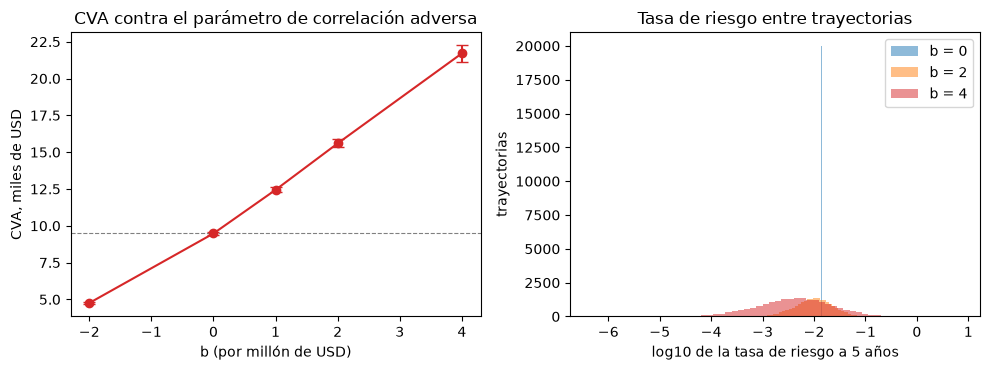

In [8]:
# Dibujar el CVA contra b con su error (izquierda) y la distribución de la tasa de riesgo a 5 años para tres valores de b (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
bs = [s[0] for s in sweep]
left.errorbar(bs, [s[1] / 1e3 for s in sweep], yerr=[2 * s[2] / 1e3 for s in sweep], fmt="o-", color="tab:red", capsize=4)
left.axhline(independent / 1e3, color="grey", lw=0.8, ls="--")
left.set_xlabel("b (por millón de USD)")
left.set_ylabel("CVA, miles de USD")
left.set_title("CVA contra el parámetro de correlación adversa")
k5 = int(np.searchsorted(report, 5.0 - 1e-9))
for b_value, color in ((0.0, "tab:blue"), (2.0, "tab:orange"), (4.0, "tab:red")):
    h = [s[3] for s in sweep if s[0] == b_value][0][:, k5]
    right.hist(np.log10(h), bins=60, alpha=0.5, color=color, label=f"b = {b_value:g}")
right.set_xlabel("log10 de la tasa de riesgo a 5 años")
right.set_ylabel("trayectorias")
right.set_title("Tasa de riesgo entre trayectorias")
right.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Supervivencia.** La curva proxy da un spread de 31 pb a un año y 51 pb a cinco, así que la supervivencia a cinco años es 95,82% y a 9,5 años 89,67%; las probabilidades de incumplimiento por tramo suman $1 - S(T)$, como deben. Toda la supervivencia y las probabilidades de incumplimiento recalculadas aquí son iguales a las versionadas hasta el último dígito.
- **CVA y DVA.** El CVA del conjunto de neteo de cuatro swaps es 9.478 USD (error de Monte Carlo 51), el DVA 4.344 USD y el valor bilateral 5.134 USD, todos iguales al documento versionado. Solo 8,8% del CVA viene de los dos primeros años: la exposición alcanza su máximo más tarde, y la probabilidad de incumplimiento crece con el tiempo.
- **La curva importa más que las trayectorias.** Reemplazar la curva proxy por un spread plano de 125 pb sube el CVA a 16.506 USD, 1,74 veces el valor con el proxy, una brecha muy por sobre el error de Monte Carlo. El proxy es un promedio de mercado AAA a A; para una contraparte de menor calificación el CVA sería aún mayor. Esta es la mayor fuente de incertidumbre del número, y es una entrada y no una elección de modelo.
- **Correlación adversa.** El barrido reproduce el versionado hasta el último dígito. Contra el CVA independiente de 9.478 USD, $b=1$ por millón de USD da 12.440 USD (+31,2%), $b=2$ da 15.595 USD (+64,5%) y $b=4$ da 21.707 USD (+129,0%); el valor de correlación favorable $b=-2$ da 4.756 USD (-49,8%). El mayor valor de la cartera es 2,09 millones de USD, así que $|b|\,w$ llega a cerca de 8 con $b=4$, una tasa de riesgo multiplicada por $e^{8}$ en la trayectoria más extrema. La calibración conserva la supervivencia de hoy: la mayor brecha entre la supervivencia promedio y la meta es 5,2e-13.
- **La independencia es un caso especial.** En $b=0$ el motor devuelve el CVA independiente bit por bit, así que un modelo de correlación adversa que no mueve el CVA cuando $b$ es cero cumple una propiedad necesaria, y se cumple.
- **El ejemplo del Apéndice.** El motor reproduce las tasas de riesgo del ejemplo del artículo hasta los cinco decimales impresos (mayor brecha 4,5e-6) y $a(t_1^*)$ hasta el dígito (-6,9128). Para $a(t_2^*)$ el motor da -7,8508 y el artículo imprime -7,8509: la brecha es 1,3e-4, 1,3 unidades del último dígito impreso. Informamos esa brecha tal cual; ambos son la raíz de la misma ecuación impresa. La regla de dos puntos da $b=0,0408$, el valor del artículo.

Lo que este cuaderno no muestra: la forma de primer incumplimiento del CVA (no implementada), una curva de crédito propia de una contraparte, ni el ejemplo de correlación adversa de ORE, que es otro modelo (un factor de crédito correlacionado con la tasa en -0,2) y no da una verificación de este. El cuaderno 08 vuelve al Apéndice como valor de referencia.

## Resumen

- El triángulo de crédito convierte un spread en una tasa de riesgo $s/\mathrm{LGD}$ y una curva de supervivencia; las probabilidades de incumplimiento por tramo son las caídas de la supervivencia.
- $\mathrm{CVA} = \sum PD\ \mathrm{LGD}\ \mathrm{EPE}$ y $\mathrm{DVA} = \sum PD_{banco}\ \mathrm{LGD}_{banco}\ \mathrm{ENE}$ sobre perfiles descontados; la respuesta descansa más en la curva de crédito que en el error de Monte Carlo.
- La tasa de riesgo de Hull y White $h = \exp(a(t) + b\,w)$ conserva la supervivencia de hoy por construcción y mueve el incumplimiento hacia las trayectorias donde la cartera vale más; aquí el CVA sube 31% con $b=1$ y 129% con $b=4$.
- El motor reproduce el ejemplo del Apéndice del artículo hasta sus dígitos impresos, con 1,3 unidades del último dígito impreso de diferencia en un valor.

**Qué probar después.** Cambia el `lgd` o el spread del banco y mira cuál de CVA y DVA se mueve; agrega solo la exposición de los dos primeros años y mira qué poco aportan los tramos cortos. Luego sigue con el cuaderno 04.

## Referencias

- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- U.S. Department of the Treasury, High Quality Market (HQM) Corporate Bond Yield Curve. https://home.treasury.gov/data/treasury-coupon-issues-and-corporate-bond-yield-curve/corporate-bond-yield-curve
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605